In [1]:
# Predict Concrete Compressive Strength

In [2]:
# Step 1: Import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [4]:
# Step 2: Load dataset

In [5]:
df = pd.read_csv("civil_regression_dataset.csv")

df.head()

,cement,water,aggregates,strength
0,335.255462,153.612508,550.715080,201.648201
1,243.976349,192.200723,345.942816,106.896167
2,151.623525,135.493297,670.793244,115.278790
3,396.217433,131.282038,247.477877,199.617536
4,395.119620,175.572228,425.190884,201.403467


In [6]:
# Step 3: Explore the dataset

In [7]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (10000, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   cement      10000 non-null  float64
 1   water       10000 non-null  float64
 2   aggregates  10000 non-null  float64
 3   strength    10000 non-null  float64
dtypes: float64(4)
memory usage: 312.6 KB

Statistical Summary:
             cement         water    aggregates      strength
count  10000.000000  10000.000000  10000.000000  10000.000000
mean     299.059983    124.839677    498.945052    174.587341
std      115.467249     43.287184    171.863298     61.303010
min      100.000208     50.002721    200.178095     20.646078
25%      199.079676     87.340459    352.243950    125.844508
50%      297.815185    124.360182    497.313302    173.929215
75%      399.719619    162.571513    646.867715    224.352731
max      499.992743    199.996391    79

In [8]:
# Step 4: Exploratory Data Analysis (EDA)

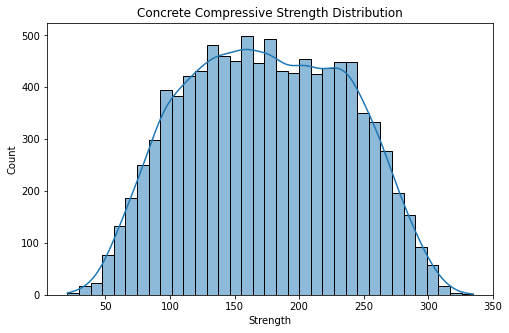

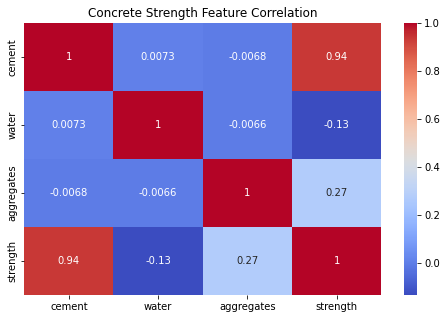

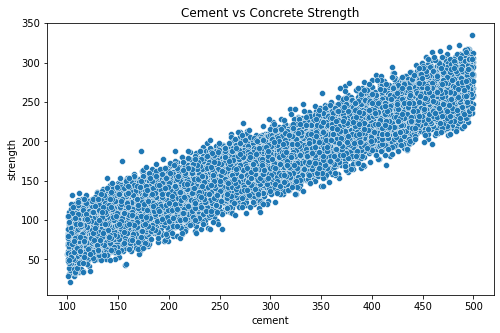

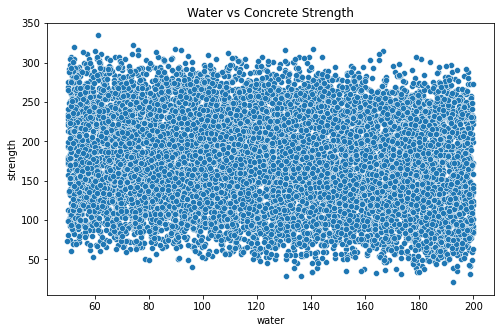

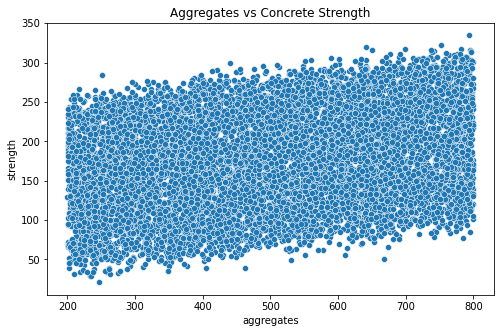

In [9]:
# Strength distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["strength"], kde=True)
plt.title("Concrete Compressive Strength Distribution")
plt.xlabel("Strength")
plt.show()

# Correlation heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Concrete Strength Feature Correlation")
plt.show()

# Cement vs Strength
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="cement", y="strength")
plt.title("Cement vs Concrete Strength")
plt.show()

# Water vs Strength
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="water", y="strength")
plt.title("Water vs Concrete Strength")
plt.show()

# Aggregates vs Strength
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="aggregates", y="strength")
plt.title("Aggregates vs Concrete Strength")
plt.show()

In [10]:
# Step 5: Define independent and dependent variables

In [11]:
X = df[["cement", "water", "aggregates"]]

y = df["strength"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
       cement       water  aggregates
0  335.255462  153.612508  550.715080
1  243.976349  192.200723  345.942816
2  151.623525  135.493297  670.793244
3  396.217433  131.282038  247.477877
4  395.119620  175.572228  425.190884

Target:
0    201.648201
1    106.896167
2    115.278790
3    199.617536
4    201.403467
Name: strength, dtype: float64


In [12]:
# Step 6: Split the dataset

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (8000, 3)
Testing Data: (2000, 3)


In [14]:
# Step 7: Build and train the Linear Regression model

In [15]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


In [16]:
# Step 8: Make predictions

In [17]:
y_pred = model.predict(X_test)

print("Actual Strength:")
print(y_test.head(10).values)

print("\nPredicted Strength:")
print(y_pred[:10])

Actual Strength:
[160.28893711 277.86793808 143.90925521 189.52535758 220.82613999
 223.58828583 218.29469225 185.38958743  72.36338585 149.89018851]

Predicted Strength:
[167.56885419 259.67070939 155.75708815 193.82379076 232.86396687
 227.86307428 236.67928221 161.93152247  98.48291912 141.75681903]


In [18]:
# Step 9: Evaluate the model

In [19]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("-------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
-------------------------
MAE: 7.956544014699427
MSE: 100.60817884093332
RMSE: 10.030362846923003
R2 Score: 0.9732266235632099


In [20]:
# Step 10: Visualize actual vs predicted strength

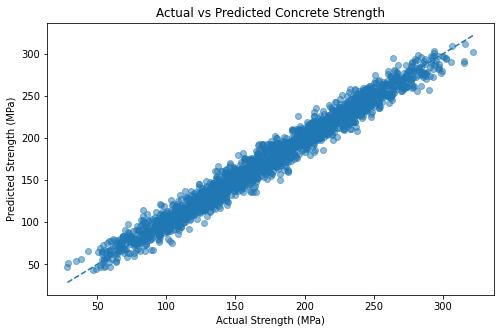

In [21]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

# Ideal prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Strength (MPa)")
plt.ylabel("Predicted Strength (MPa)")
plt.title("Actual vs Predicted Concrete Strength")

plt.show()

In [22]:
# Step 11: Predict strength for a new concrete mixture

In [23]:
new_mixture = pd.DataFrame({
    "cement": [350],
    "water": [150],
    "aggregates": [500]
})

predicted_strength = model.predict(new_mixture)

print(
    "Predicted Concrete Compressive Strength:",
    round(predicted_strength[0], 2),
    "MPa"
)

Predicted Concrete Compressive Strength: 195.35 MPa


In [24]:
# Step 12: Display feature coefficients

In [25]:
regressor = model.named_steps["regressor"]

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": regressor.coef_
})

print(coefficients)

print("Intercept:", regressor.intercept_)

      Feature  Coefficient
0      cement    57.573754
1       water    -8.297284
2  aggregates    17.160427
Intercept: 174.52477223636163
